In [1]:
%pip install xgboost

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [4]:
# Import libraries
import numpy as np
import pandas as pd
import time

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

In [5]:
import joblib

# Load preprocessed data
data = joblib.load("../models/preprocessed_data.pkl")

X_train_processed = data["X_train"]
X_test_processed = data["X_test"]

y_train = data["y_train"]
y_test = data["y_test"]

preprocessor = data["preprocessor"]

print("Data loaded successfully!")

print("Training data:", X_train_processed.shape)
print("Testing data:", X_test_processed.shape)

Data loaded successfully!
Training data: (81613, 2373)
Testing data: (20153, 2373)


In [6]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "XGBoost": XGBClassifier(
        n_estimators=200,
        max_depth=5,
        learning_rate=0.1,
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    )
}

print("Three models defined successfully!")

Three models defined successfully!


In [7]:
results = []

for name, model in models.items():

    print("Training:", name)

    start_time = time.time()

    model.fit(X_train_processed, y_train)

    training_time = time.time() - start_time

    y_pred = model.predict(X_test_processed)
    y_prob = model.predict_proba(X_test_processed)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "Training Time (sec)": round(training_time, 2)
    })

    print("Completed:", name)
    print("-" * 40)

results_df = pd.DataFrame(results)

print("\nMODEL COMPARISON")
display(results_df.round(4))

Training: Logistic Regression
Completed: Logistic Regression
----------------------------------------
Training: Random Forest
Completed: Random Forest
----------------------------------------
Training: XGBoost
Completed: XGBoost
----------------------------------------

MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Training Time (sec)
0,Logistic Regression,0.6385,0.1545,0.5337,0.2396,0.6305,3.55
1,Random Forest,0.8933,1.0000,0.0005,0.0009,0.6464,82.23
2,XGBoost,0.8932,0.4865,0.0084,0.0165,0.6724,1.80


In [9]:
# Calculate class imbalance ratio

negative = (y_train == 0).sum()
positive = (y_train == 1).sum()

scale_pos_weight = negative / positive

print("Negative cases:", negative)
print("Positive cases:", positive)
print("Scale positive weight:", scale_pos_weight)

Negative cases: 72407
Positive cases: 9206
Scale positive weight: 7.865196610905931


In [10]:
xgb_balanced = XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    scale_pos_weight=scale_pos_weight,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

xgb_balanced.fit(X_train_processed, y_train)

# Predict probabilities
y_prob_balanced = xgb_balanced.predict_proba(
    X_test_processed
)[:, 1]

# Use a lower threshold
threshold = 0.3

y_pred_balanced = (
    y_prob_balanced >= threshold
).astype(int)

In [11]:
print("Accuracy:", accuracy_score(y_test, y_pred_balanced))
print("Precision:", precision_score(y_test, y_pred_balanced))
print("Recall:", recall_score(y_test, y_pred_balanced))
print("F1 Score:", f1_score(y_test, y_pred_balanced))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_balanced))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_balanced))

Accuracy: 0.22944474768024611
Precision: 0.11702736745677315
Recall: 0.9502556950255695
F1 Score: 0.20839068155171536
ROC-AUC: 0.6688082232301168

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.14      0.25     18002
           1       0.12      0.95      0.21      2151

    accuracy                           0.23     20153
   macro avg       0.54      0.55      0.23     20153
weighted avg       0.87      0.23      0.25     20153



In [27]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

thresholds = [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]

threshold_results = []

for threshold in thresholds:

    y_pred = (
        y_prob_balanced >= threshold
    ).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1 Score": f1_score(y_test, y_pred)
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(4))

,Threshold,Accuracy,Precision,Recall,F1 Score
0,0.2,0.1340,0.1091,0.9921,0.1965
1,0.3,0.2294,0.1170,0.9503,0.2084
2,0.4,0.4455,0.1384,0.8024,0.2360
3,0.5,0.6540,0.1704,0.5793,0.2633
4,0.6,0.8106,0.2244,0.3152,0.2621
5,0.7,0.8790,0.3134,0.1120,0.1651
6,0.8,0.8916,0.3878,0.0265,0.0496


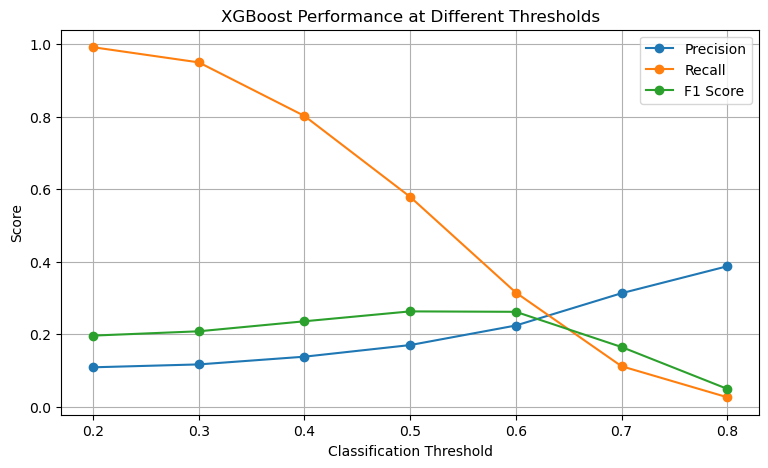

In [28]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["F1 Score"],
    marker="o",
    label="F1 Score"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("XGBoost Performance at Different Thresholds")

plt.legend()
plt.grid(True)
plt.show()

Confusion Matrix:
[[11935  6067]
 [  905  1246]]


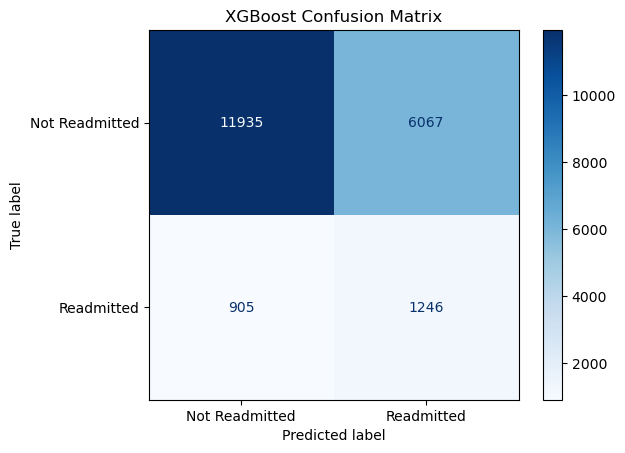

In [29]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Predictions using threshold 0.5
y_pred_final = (y_prob_balanced >= 0.5).astype(int)

# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred_final)

print("Confusion Matrix:")
print(cm)

# Visualise
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not Readmitted", "Readmitted"]
)

disp.plot(cmap="Blues", values_format="d")

plt.title("XGBoost Confusion Matrix")
plt.show()

In [30]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

print("FINAL XGBOOST PERFORMANCE")
print("--------------------------")

print("Accuracy:",
      round(accuracy_score(y_test, y_pred_final), 4))

print("Precision:",
      round(precision_score(y_test, y_pred_final), 4))

print("Recall:",
      round(recall_score(y_test, y_pred_final), 4))

print("F1 Score:",
      round(f1_score(y_test, y_pred_final), 4))

print("ROC-AUC:",
      round(roc_auc_score(y_test, y_prob_balanced), 4))

FINAL XGBOOST PERFORMANCE
--------------------------
Accuracy: 0.654
Precision: 0.1704
Recall: 0.5793
F1 Score: 0.2633
ROC-AUC: 0.6688


In [31]:
# Generate predictions from original models

comparison_results = []

for name, model in models.items():

    y_pred = model.predict(X_test_processed)
    y_prob = model.predict_proba(X_test_processed)[:, 1]

    comparison_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

# Add balanced XGBoost
comparison_results.append({
    "Model": "Balanced XGBoost",
    "Accuracy": accuracy_score(y_test, y_pred_final),
    "Precision": precision_score(y_test, y_pred_final),
    "Recall": recall_score(y_test, y_pred_final),
    "F1 Score": f1_score(y_test, y_pred_final),
    "ROC-AUC": roc_auc_score(y_test, y_prob_balanced)
})

comparison_df = pd.DataFrame(comparison_results)

display(comparison_df.round(4))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.6385,0.1545,0.5337,0.2396,0.6305
1,Random Forest,0.8933,1.0000,0.0005,0.0009,0.6464
2,XGBoost,0.8932,0.4865,0.0084,0.0165,0.6724
3,Balanced XGBoost,0.6540,0.1704,0.5793,0.2633,0.6688


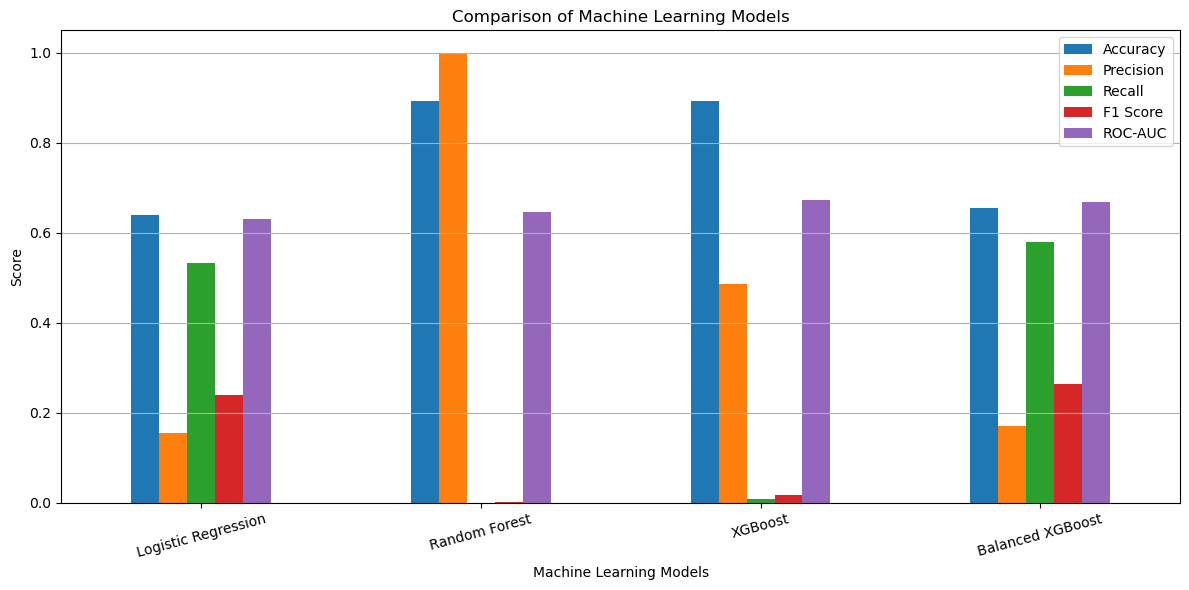

In [32]:
metrics = ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"]

comparison_df.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Comparison of Machine Learning Models")
plt.ylabel("Score")
plt.xlabel("Machine Learning Models")
plt.xticks(rotation=15)
plt.legend(loc="best")
plt.grid(axis="y")
plt.tight_layout()
plt.show()

In [33]:
# Convert ID columns into categorical features

id_columns = [
    "admission_type_id",
    "discharge_disposition_id",
    "admission_source_id"
]

for col in id_columns:
    X_train[col] = X_train[col].astype(str)
    X_test[col] = X_test[col].astype(str)

# Identify numerical columns
numerical_cols = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

# Identify categorical columns
categorical_cols = X_train.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical columns:", len(numerical_cols))
print(numerical_cols)

print("\nCategorical columns:", len(categorical_cols))
print(categorical_cols)

Numerical columns: 9
['encounter_id', 'time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses']

Categorical columns: 36
['race', 'gender', 'age', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'payer_code', 'medical_specialty', 'diag_1', 'diag_2', 'diag_3', 'max_glu_serum', 'A1Cresult', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone', 'change', 'diabetesMed']


In [34]:
import pandas as pd

# Load original dataset
df = pd.read_csv("../datasets/dataset1/diabetic_data.csv")

# Replace missing value symbols
df.replace("?", pd.NA, inplace=True)

# Preserve patient IDs
patient_ids = df["patient_nbr"].copy()

# Remove identifiers
data = df.drop(
    columns=["encounter_id", "patient_nbr"]
).copy()

# Remove unnecessary columns
data.drop(
    columns=["weight", "examide", "citoglipton"],
    inplace=True,
    errors="ignore"
)

# Create target variable
data["readmitted"] = (
    data["readmitted"] == "<30"
).astype(int)

# Handle missing categorical values
for col in [
    "medical_specialty", "payer_code", "race",
    "diag_1", "diag_2", "diag_3"
]:
    data[col] = data[col].fillna("Unknown")

data["max_glu_serum"] = data["max_glu_serum"].fillna("Not Tested")
data["A1Cresult"] = data["A1Cresult"].fillna("Not Tested")

# Separate features and target
X = data.drop(columns=["readmitted"])
y = data["readmitted"]

print("Data loaded:", X.shape)

Data loaded: (101766, 44)


In [35]:
from sklearn.model_selection import GroupShuffleSplit

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=patient_ids)
)

X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (81613, 44)
Testing: (20153, 44)


In [36]:
id_columns = [
    "admission_type_id",
    "discharge_disposition_id",
    "admission_source_id"
]

for col in id_columns:
    X_train[col] = X_train[col].astype(str)
    X_test[col] = X_test[col].astype(str)

numerical_cols = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_cols = X_train.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical columns:", len(numerical_cols))
print("Categorical columns:", len(categorical_cols))

Numerical columns: 8
Categorical columns: 36


In [37]:
from sklearn.model_selection import GroupShuffleSplit

# Get patient IDs corresponding to training records
train_patient_ids = patient_ids.iloc[train_idx]

# Split training data into training and validation
val_splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

subtrain_idx, val_idx = next(
    val_splitter.split(
        X_train,
        y_train,
        groups=train_patient_ids
    )
)

X_subtrain = X_train.iloc[subtrain_idx].copy()
X_val = X_train.iloc[val_idx].copy()

y_subtrain = y_train.iloc[subtrain_idx]
y_val = y_train.iloc[val_idx]

print("Training:", X_subtrain.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Training: (65146, 44)
Validation: (16467, 44)
Testing: (20153, 44)


In [38]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

numerical_transformer = Pipeline(steps=[
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_cols),
        ("cat", categorical_transformer, categorical_cols)
    ]
)

# Fit only on training data
X_subtrain_processed = preprocessor.fit_transform(X_subtrain)

# Transform validation and testing data
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

print("Training:", X_subtrain_processed.shape)
print("Validation:", X_val_processed.shape)
print("Testing:", X_test_processed.shape)

Training: (65146, 2344)
Validation: (16467, 2344)
Testing: (20153, 2344)


In [39]:
subtrain_patients = set(
    train_patient_ids.iloc[subtrain_idx]
)

val_patients = set(
    train_patient_ids.iloc[val_idx]
)

test_patients = set(
    patient_ids.iloc[test_idx]
)

print("Training and validation overlap:",
      len(subtrain_patients & val_patients))

print("Training and testing overlap:",
      len(subtrain_patients & test_patients))

print("Validation and testing overlap:",
      len(val_patients & test_patients))

Training and validation overlap: 0
Training and testing overlap: 0
Validation and testing overlap: 0


In [40]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

In [41]:
C_values = [0.01, 0.1, 1, 10]

lr_results = []
lr_models = {}

for c in C_values:

    model = LogisticRegression(
        C=c,
        max_iter=1500,
        class_weight="balanced",
        random_state=42,
        solver="liblinear"
    )

    model.fit(X_subtrain_processed, y_subtrain)

    # Validation probabilities
    y_val_prob = model.predict_proba(
        X_val_processed
    )[:, 1]

    # Default threshold
    y_val_pred = (y_val_prob >= 0.5).astype(int)

    lr_models[c] = model

    lr_results.append({
        "C": c,
        "Accuracy": accuracy_score(y_val, y_val_pred),
        "Precision": precision_score(y_val, y_val_pred, zero_division=0),
        "Recall": recall_score(y_val, y_val_pred, zero_division=0),
        "F1 Score": f1_score(y_val, y_val_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_val, y_val_prob)
    })

lr_results_df = pd.DataFrame(lr_results)

display(lr_results_df.round(4))

,C,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,0.01,0.6738,0.1894,0.5679,0.2841,0.6748
1,0.10,0.6626,0.1803,0.5525,0.2718,0.6657
2,1.00,0.6553,0.1747,0.5434,0.2644,0.6480
3,10.00,0.6486,0.1696,0.5344,0.2574,0.6364


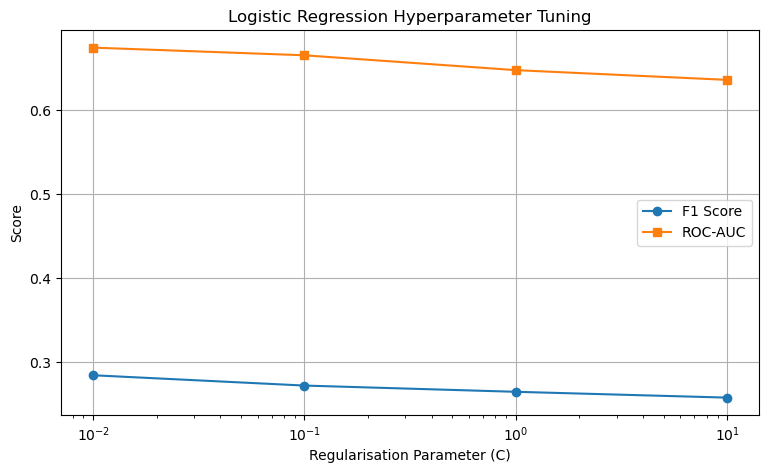

In [42]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(
    lr_results_df["C"],
    lr_results_df["F1 Score"],
    marker="o",
    label="F1 Score"
)

plt.plot(
    lr_results_df["C"],
    lr_results_df["ROC-AUC"],
    marker="s",
    label="ROC-AUC"
)

plt.xscale("log")
plt.xlabel("Regularisation Parameter (C)")
plt.ylabel("Score")
plt.title("Logistic Regression Hyperparameter Tuning")
plt.legend()
plt.grid(True)
plt.show()

In [43]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

In [44]:
rf_configs = [
    {
        "n_estimators": 150,
        "max_depth": 15,
        "min_samples_leaf": 5,
        "class_weight": "balanced"
    },
    {
        "n_estimators": 150,
        "max_depth": 25,
        "min_samples_leaf": 5,
        "class_weight": "balanced"
    },
    {
        "n_estimators": 150,
        "max_depth": None,
        "min_samples_leaf": 10,
        "class_weight": "balanced_subsample"
    },
    {
        "n_estimators": 200,
        "max_depth": 20,
        "min_samples_leaf": 10,
        "class_weight": "balanced_subsample"
    }
]

In [45]:
rf_results = []
rf_models = {}

for i, config in enumerate(rf_configs):

    print("Training configuration:", i + 1)

    model = RandomForestClassifier(
        **config,
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_subtrain_processed, y_subtrain)

    y_val_prob = model.predict_proba(
        X_val_processed
    )[:, 1]

    y_val_pred = (y_val_prob >= 0.5).astype(int)

    rf_models[i + 1] = model

    rf_results.append({
        "Configuration": i + 1,
        "Max Depth": str(config["max_depth"]),
        "Min Samples Leaf": config["min_samples_leaf"],
        "Class Weight": config["class_weight"],
        "Accuracy": accuracy_score(y_val, y_val_pred),
        "Precision": precision_score(y_val, y_val_pred, zero_division=0),
        "Recall": recall_score(y_val, y_val_pred, zero_division=0),
        "F1 Score": f1_score(y_val, y_val_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_val, y_val_prob)
    })

    print("Completed configuration:", i + 1)

rf_results_df = pd.DataFrame(rf_results)

display(rf_results_df.round(4))

Training configuration: 1
Completed configuration: 1
Training configuration: 2
Completed configuration: 2
Training configuration: 3
Completed configuration: 3
Training configuration: 4
Completed configuration: 4


,Configuration,Max Depth,Min Samples Leaf,Class Weight,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,1,15,5,balanced,0.6603,0.1824,0.5685,0.2761,0.6724
1,2,25,5,balanced,0.7039,0.1949,0.5104,0.2821,0.6752
2,3,None,10,balanced_subsample,0.7136,0.1984,0.4976,0.2837,0.6790
3,4,20,10,balanced_subsample,0.6698,0.1860,0.5621,0.2795,0.6759


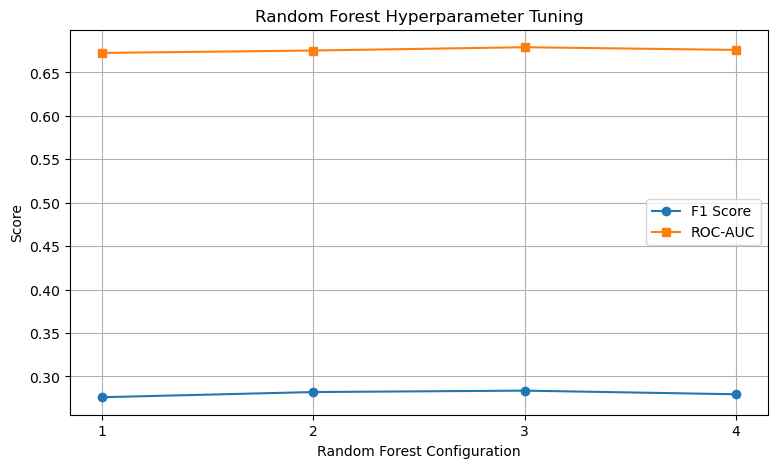

In [46]:
plt.figure(figsize=(9, 5))

plt.plot(
    rf_results_df["Configuration"],
    rf_results_df["F1 Score"],
    marker="o",
    label="F1 Score"
)

plt.plot(
    rf_results_df["Configuration"],
    rf_results_df["ROC-AUC"],
    marker="s",
    label="ROC-AUC"
)

plt.xlabel("Random Forest Configuration")
plt.ylabel("Score")
plt.title("Random Forest Hyperparameter Tuning")

plt.xticks([1, 2, 3, 4])
plt.legend()
plt.grid(True)
plt.show()

In [47]:
{
    "n_estimators": 150,
    "max_depth": None,
    "min_samples_leaf": 10,
    "class_weight": "balanced_subsample"
}

{'n_estimators': 150,
 'max_depth': None,
 'min_samples_leaf': 10,
 'class_weight': 'balanced_subsample'}

In [48]:
from xgboost import XGBClassifier

xgb_configs = [
    {
        "n_estimators": 200,
        "max_depth": 3,
        "learning_rate": 0.05,
        "min_child_weight": 5,
        "subsample": 0.8
    },
    {
        "n_estimators": 300,
        "max_depth": 4,
        "learning_rate": 0.05,
        "min_child_weight": 3,
        "subsample": 0.8
    },
    {
        "n_estimators": 300,
        "max_depth": 5,
        "learning_rate": 0.03,
        "min_child_weight": 5,
        "subsample": 0.9
    },
    {
        "n_estimators": 400,
        "max_depth": 4,
        "learning_rate": 0.03,
        "min_child_weight": 3,
        "subsample": 0.9
    }
]

In [49]:
negative = (y_subtrain == 0).sum()
positive = (y_subtrain == 1).sum()

scale_pos_weight = negative / positive

print("Scale positive weight:", scale_pos_weight)

Scale positive weight: 7.88879792604721


In [50]:
xgb_results = []
xgb_models = {}

for i, config in enumerate(xgb_configs):

    print("Training configuration:", i + 1)

    model = XGBClassifier(
        **config,
        scale_pos_weight=scale_pos_weight,
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_subtrain_processed, y_subtrain)

    y_val_prob = model.predict_proba(
        X_val_processed
    )[:, 1]

    y_val_pred = (y_val_prob >= 0.5).astype(int)

    xgb_models[i + 1] = model

    xgb_results.append({
        "Configuration": i + 1,
        "Accuracy": accuracy_score(y_val, y_val_pred),
        "Precision": precision_score(y_val, y_val_pred, zero_division=0),
        "Recall": recall_score(y_val, y_val_pred, zero_division=0),
        "F1 Score": f1_score(y_val, y_val_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_val, y_val_prob)
    })

    print("Completed configuration:", i + 1)

xgb_results_df = pd.DataFrame(xgb_results)

display(xgb_results_df.round(4))

Training configuration: 1
Completed configuration: 1
Training configuration: 2
Completed configuration: 2
Training configuration: 3
Completed configuration: 3
Training configuration: 4
Completed configuration: 4


,Configuration,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,1,0.6401,0.1816,0.6153,0.2805,0.6775
1,2,0.6542,0.1844,0.5940,0.2814,0.6800
2,3,0.6581,0.1850,0.5871,0.2813,0.6789
3,4,0.6509,0.1843,0.6020,0.2822,0.6783


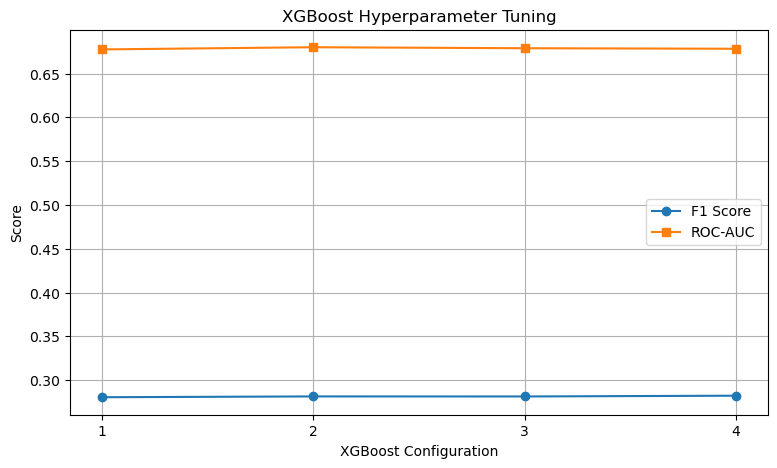

In [51]:
plt.figure(figsize=(9, 5))

plt.plot(
    xgb_results_df["Configuration"],
    xgb_results_df["F1 Score"],
    marker="o",
    label="F1 Score"
)

plt.plot(
    xgb_results_df["Configuration"],
    xgb_results_df["ROC-AUC"],
    marker="s",
    label="ROC-AUC"
)

plt.xlabel("XGBoost Configuration")
plt.ylabel("Score")
plt.title("XGBoost Hyperparameter Tuning")

plt.xticks([1, 2, 3, 4])
plt.legend()
plt.grid(True)
plt.show()

In [52]:
display(
    xgb_results_df.sort_values(
        by="F1 Score",
        ascending=False
    ).round(4)
)

,Configuration,Accuracy,Precision,Recall,F1 Score,ROC-AUC
3,4,0.6509,0.1843,0.6020,0.2822,0.6783
1,2,0.6542,0.1844,0.5940,0.2814,0.6800
2,3,0.6581,0.1850,0.5871,0.2813,0.6789
0,1,0.6401,0.1816,0.6153,0.2805,0.6775


In [53]:
{
    "n_estimators": 400,
    "max_depth": 4,
    "learning_rate": 0.03,
    "min_child_weight": 3,
    "subsample": 0.9
}

{'n_estimators': 400,
 'max_depth': 4,
 'learning_rate': 0.03,
 'min_child_weight': 3,
 'subsample': 0.9}

In [54]:
best_lr = lr_models[0.01]
best_rf = rf_models[3]
best_xgb = xgb_models[4]

best_models = {
    "Tuned Logistic Regression": best_lr,
    "Tuned Random Forest": best_rf,
    "Tuned XGBoost": best_xgb
}

tuned_results = []

for name, model in best_models.items():

    y_pred = model.predict(X_val_processed)
    y_prob = model.predict_proba(X_val_processed)[:, 1]

    tuned_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, y_pred),
        "Precision": precision_score(y_val, y_pred, zero_division=0),
        "Recall": recall_score(y_val, y_pred, zero_division=0),
        "F1 Score": f1_score(y_val, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_val, y_prob)
    })

tuned_results_df = pd.DataFrame(tuned_results)

display(tuned_results_df.round(4))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Tuned Logistic Regression,0.6738,0.1894,0.5679,0.2841,0.6748
1,Tuned Random Forest,0.7136,0.1984,0.4976,0.2837,0.6790
2,Tuned XGBoost,0.6509,0.1843,0.6020,0.2822,0.6783


In [55]:
%pip install imbalanced-learn

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [56]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(
    sampling_strategy=0.5,
    random_state=42
)

X_train_smote, y_train_smote = smote.fit_resample(
    X_subtrain_processed,
    y_subtrain
)

print("Before SMOTE:")
print(y_subtrain.value_counts())

print("\nAfter SMOTE:")
print(y_train_smote.value_counts())

Before SMOTE:
readmitted
0    57817
1     7329
Name: count, dtype: int64

After SMOTE:
readmitted
0    57817
1    28908
Name: count, dtype: int64


In [57]:
from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Train XGBoost using SMOTE-resampled data
xgb_smote = XGBClassifier(
    n_estimators=400,
    max_depth=4,
    learning_rate=0.03,
    min_child_weight=3,
    subsample=0.9,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

xgb_smote.fit(X_train_smote, y_train_smote)

# Predict on original validation data
y_val_prob_smote = xgb_smote.predict_proba(
    X_val_processed
)[:, 1]

y_val_pred_smote = (
    y_val_prob_smote >= 0.5
).astype(int)

# Evaluate
smote_results = {
    "Model": "XGBoost with SMOTE",
    "Accuracy": accuracy_score(y_val, y_val_pred_smote),
    "Precision": precision_score(y_val, y_val_pred_smote, zero_division=0),
    "Recall": recall_score(y_val, y_val_pred_smote, zero_division=0),
    "F1 Score": f1_score(y_val, y_val_pred_smote, zero_division=0),
    "ROC-AUC": roc_auc_score(y_val, y_val_prob_smote)
}

display(pd.DataFrame([smote_results]).round(4))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,XGBoost with SMOTE,0.886,0.0,0.0,0.0,0.6593


In [58]:
comparison = []

for name, model in {
    "Tuned XGBoost": best_xgb,
    "XGBoost with SMOTE": xgb_smote
}.items():

    if name == "XGBoost with SMOTE":
        y_prob = y_val_prob_smote
        y_pred = y_val_pred_smote
    else:
        y_prob = model.predict_proba(X_val_processed)[:, 1]
        y_pred = (y_prob >= 0.5).astype(int)

    comparison.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, y_pred),
        "Precision": precision_score(y_val, y_pred, zero_division=0),
        "Recall": recall_score(y_val, y_pred, zero_division=0),
        "F1 Score": f1_score(y_val, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_val, y_prob)
    })

smote_comparison_df = pd.DataFrame(comparison)

display(smote_comparison_df.round(4))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Tuned XGBoost,0.6509,0.1843,0.602,0.2822,0.6783
1,XGBoost with SMOTE,0.8860,0.0000,0.000,0.0000,0.6593


In [59]:
import numpy as np
import pandas as pd

print("SMOTE prediction probability statistics:")

print(pd.Series(y_val_prob_smote).describe())

print("\nNumber of predicted readmissions at different thresholds:")

for threshold in [0.1, 0.2, 0.3, 0.4, 0.5]:

    predictions = (
        y_val_prob_smote >= threshold
    ).astype(int)

    print(
        f"Threshold {threshold}: "
        f"{predictions.sum()} predicted readmissions"
    )

SMOTE prediction probability statistics:
count    16467.000000
mean         0.125193
std          0.052610
min          0.028846
25%          0.090224
50%          0.115922
75%          0.138954
max          0.434185
dtype: float64

Number of predicted readmissions at different thresholds:
Threshold 0.1: 9530 predicted readmissions
Threshold 0.2: 1911 predicted readmissions
Threshold 0.3: 281 predicted readmissions
Threshold 0.4: 15 predicted readmissions
Threshold 0.5: 0 predicted readmissions


In [60]:
threshold_results_smote = []

for threshold in [0.1, 0.2, 0.3, 0.4, 0.5]:

    predictions = (
        y_val_prob_smote >= threshold
    ).astype(int)

    threshold_results_smote.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_val, predictions),
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_val, predictions, zero_division=0
        )
    })

smote_threshold_df = pd.DataFrame(
    threshold_results_smote
)

display(smote_threshold_df.round(4))

,Threshold,Accuracy,Precision,Recall,F1 Score
0,0.1,0.4808,0.1499,0.7613,0.2505
1,0.2,0.8247,0.2360,0.2403,0.2381
2,0.3,0.8849,0.4662,0.0698,0.1214
3,0.4,0.8863,0.6667,0.0053,0.0106
4,0.5,0.8860,0.0000,0.0000,0.0000


In [61]:
from sklearn.metrics import precision_recall_curve

# Get probabilities from best tuned XGBoost
y_val_prob_best = best_xgb.predict_proba(
    X_val_processed
)[:, 1]

# Calculate precision and recall at different thresholds
precision, recall, thresholds = precision_recall_curve(
    y_val,
    y_val_prob_best
)

# Calculate F1 score
f1_scores = (
    2 * precision[:-1] * recall[:-1] /
    (precision[:-1] + recall[:-1] + 1e-10)
)

# Find threshold with maximum F1
best_index = f1_scores.argmax()

best_threshold = thresholds[best_index]

print("Best Threshold:", round(best_threshold, 4))
print("Best Precision:", round(precision[best_index], 4))
print("Best Recall:", round(recall[best_index], 4))
print("Best F1 Score:", round(f1_scores[best_index], 4))

Best Threshold: 0.5376
Best Precision: 0.2051
Best Recall: 0.48
Best F1 Score: 0.2874


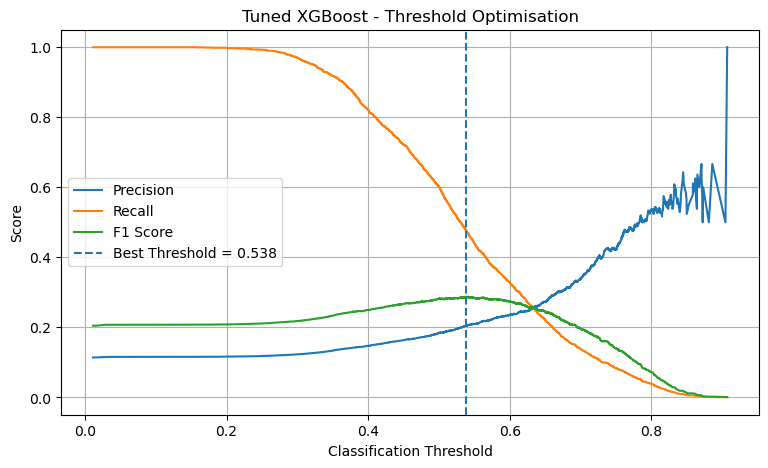

In [62]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(
    thresholds,
    precision[:-1],
    label="Precision"
)

plt.plot(
    thresholds,
    recall[:-1],
    label="Recall"
)

plt.plot(
    thresholds,
    f1_scores,
    label="F1 Score"
)

plt.axvline(
    best_threshold,
    linestyle="--",
    label=f"Best Threshold = {best_threshold:.3f}"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Tuned XGBoost - Threshold Optimisation")

plt.legend()
plt.grid(True)
plt.show()

In [63]:
print("BEST XGBOOST VALIDATION RESULTS")
print("--------------------------------")

print("Best Threshold:", round(best_threshold, 4))
print("Precision:", round(precision[best_index], 4))
print("Recall:", round(recall[best_index], 4))
print("F1 Score:", round(f1_scores[best_index], 4))

BEST XGBOOST VALIDATION RESULTS
--------------------------------
Best Threshold: 0.5376
Precision: 0.2051
Recall: 0.48
F1 Score: 0.2874


In [64]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Predict probabilities on test data
y_test_prob = best_xgb.predict_proba(
    X_test_processed
)[:, 1]

# Apply validation-selected threshold
y_test_pred = (
    y_test_prob >= best_threshold
).astype(int)

# Calculate final metrics
print("FINAL TEST PERFORMANCE")
print("-----------------------")

print("Accuracy:", round(
    accuracy_score(y_test, y_test_pred), 4
))

print("Precision:", round(
    precision_score(y_test, y_test_pred, zero_division=0), 4
))

print("Recall:", round(
    recall_score(y_test, y_test_pred, zero_division=0), 4
))

print("F1 Score:", round(
    f1_score(y_test, y_test_pred, zero_division=0), 4
))

print("ROC-AUC:", round(
    roc_auc_score(y_test, y_test_prob), 4
))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_test_pred,
    target_names=["Not Readmitted", "Readmitted"]
))

FINAL TEST PERFORMANCE
-----------------------
Accuracy: 0.7302
Precision: 0.1917
Recall: 0.4751
F1 Score: 0.2732
ROC-AUC: 0.6745

Classification Report:
                precision    recall  f1-score   support

Not Readmitted       0.92      0.76      0.83     18002
    Readmitted       0.19      0.48      0.27      2151

      accuracy                           0.73     20153
     macro avg       0.56      0.62      0.55     20153
  weighted avg       0.85      0.73      0.77     20153



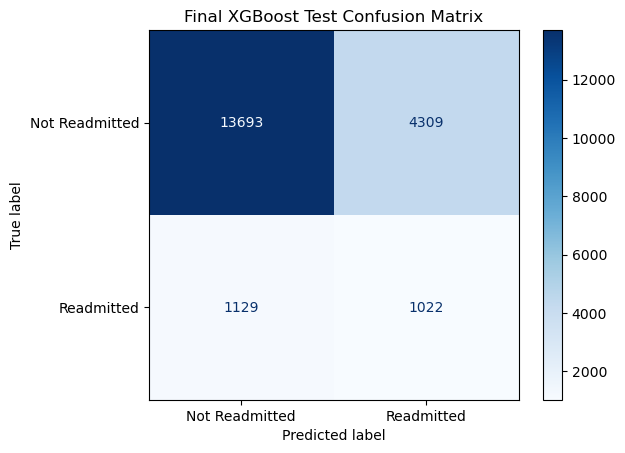

In [65]:
cm = confusion_matrix(y_test, y_test_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not Readmitted", "Readmitted"]
)

disp.plot(cmap="Blues", values_format="d")

plt.title("Final XGBoost Test Confusion Matrix")
plt.show()

In [66]:
# Get feature importance from final XGBoost model

importance = best_xgb.feature_importances_

feature_names = preprocessor.get_feature_names_out()

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print("Top 20 Important Features:")

display(importance_df.head(20))

Top 20 Important Features:


,Feature,Importance
6,num__number_inpatient,0.029381
35,cat__discharge_disposition_id_1,0.024705
37,cat__discharge_disposition_id_11,0.013322
48,cat__discharge_disposition_id_22,0.011254
840,cat__diag_1_V57,0.008930
54,cat__discharge_disposition_id_3,0.007076
56,cat__discharge_disposition_id_5,0.006505
2342,cat__diabetesMed_No,0.005642
39,cat__discharge_disposition_id_13,0.005432
430,cat__diag_1_428,0.005410


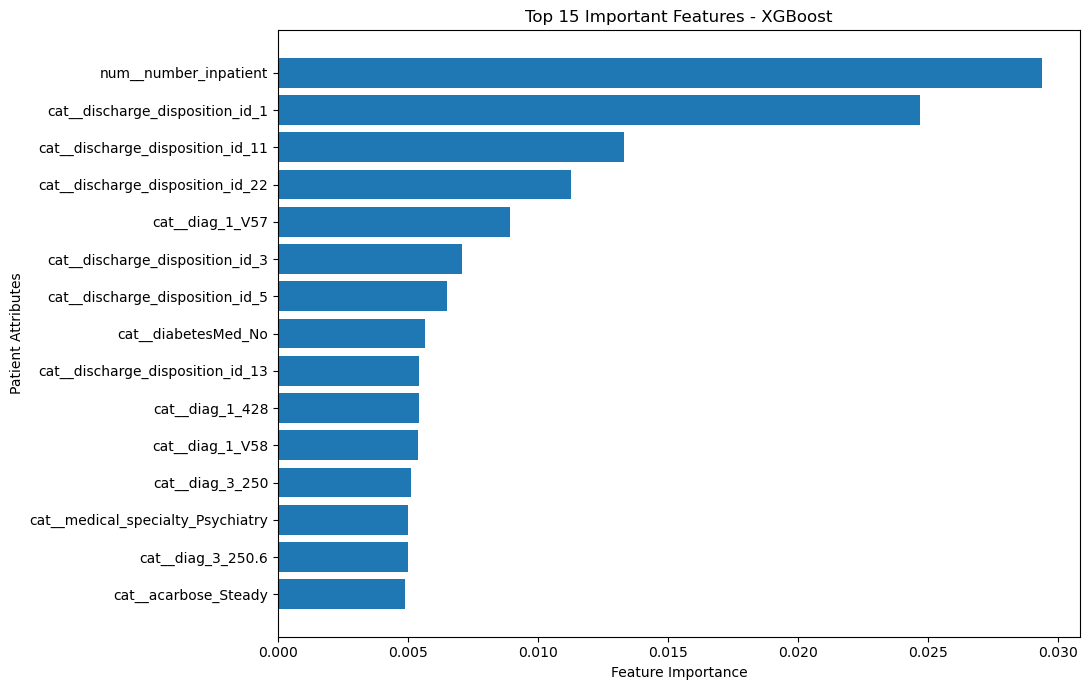

In [67]:
plt.figure(figsize=(11, 7))

top_features = importance_df.head(15).sort_values(
    by="Importance"
)

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Patient Attributes")
plt.title("Top 15 Important Features - XGBoost")

plt.tight_layout()
plt.show()

In [68]:
import os
import joblib

# Create models folder if it doesn't exist
os.makedirs("../models", exist_ok=True)

# Save model
joblib.dump(
    best_xgb,
    "../models/xgboost_model.pkl"
)

# Save preprocessing pipeline
joblib.dump(
    preprocessor,
    "../models/preprocessor.pkl"
)

# Save classification threshold
joblib.dump(
    best_threshold,
    "../models/threshold.pkl"
)

print("Model saved successfully!")

Model saved successfully!


In [2]:
import pandas as pd
import matplotlib.pyplot as plt



In [22]:
print("X_train:", "X_train" in globals())
print("X_test:", "X_test" in globals())
print("X:", "X" in globals())
print("y:", "y" in globals())

X_train: False
X_test: False
X: False
y: False


In [23]:
import pandas as pd
import numpy as np

# Load dataset
df = pd.read_csv("../datasets/dataset1/diabetic_data.csv")

# Replace missing value markers
df.replace("?", np.nan, inplace=True)

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (101766, 50)


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),NaN,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),NaN,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [24]:
# Create target variable
y = (df["readmitted"] == "<30").astype(int)

# Preserve patient IDs for group splitting
groups = df["patient_nbr"].copy()

# Remove target and identifier columns
X = df.drop(columns=["readmitted", "patient_nbr"])

# Remove unnecessary columns
X.drop(columns=["examide", "citoglipton", "weight"], inplace=True)

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (101766, 45)
y shape: (101766,)


In [25]:
from sklearn.model_selection import GroupShuffleSplit

# Split patients, not individual encounters
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()

y_train = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

# Verify no patient overlap
train_patients = groups.iloc[train_idx]
test_patients = groups.iloc[test_idx]

print("Common patients:", len(set(train_patients) & set(test_patients)))

Training data: (81613, 45)
Testing data: (20153, 45)
Common patients: 0


In [26]:
from sklearn.model_selection import GroupShuffleSplit

# Get patient IDs belonging to the training set
train_groups = groups.iloc[train_idx]

# Split training data into sub-training and validation sets
splitter_val = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

subtrain_idx, val_idx = next(
    splitter_val.split(X_train, y_train, groups=train_groups)
)

X_subtrain = X_train.iloc[subtrain_idx].copy()
X_val = X_train.iloc[val_idx].copy()

y_subtrain = y_train.iloc[subtrain_idx].copy()
y_val = y_train.iloc[val_idx].copy()

print("Sub-training data:", X_subtrain.shape)
print("Validation data:", X_val.shape)
print("Testing data:", X_test.shape)

# Verify patient separation
subtrain_patients = train_groups.iloc[subtrain_idx]
val_patients = train_groups.iloc[val_idx]

print(
    "Common patients (train-validation):",
    len(set(subtrain_patients) & set(val_patients))
)

print(
    "Common patients (validation-test):",
    len(set(val_patients) & set(test_patients))
)

Sub-training data: (65146, 45)
Validation data: (16467, 45)
Testing data: (20153, 45)
Common patients (train-validation): 0
Common patients (validation-test): 0


In [69]:
# Check important variables
variables = [
    "best_lr",
    "best_rf",
    "best_xgb",
    "preprocessor",
    "X_test_processed",
    "X_val_processed",
    "best_threshold"
]

for var in variables:
    print(f"{var}: {'Available' if var in globals() else 'Missing'}")

best_lr: Available
best_rf: Available
best_xgb: Available
preprocessor: Available
X_test_processed: Available
X_val_processed: Available
best_threshold: Available


In [70]:
import pandas as pd
import matplotlib.pyplot as plt

# Get feature importance from the trained XGBoost model
importance = best_xgb.feature_importances_

# Get transformed feature names
feature_names = preprocessor.get_feature_names_out()

# Create DataFrame
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
})

# Sort by importance
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

# Display top 20 features
display(importance_df.head(20).round(4))

,Feature,Importance
6,num__number_inpatient,0.0294
35,cat__discharge_disposition_id_1,0.0247
37,cat__discharge_disposition_id_11,0.0133
48,cat__discharge_disposition_id_22,0.0113
840,cat__diag_1_V57,0.0089
54,cat__discharge_disposition_id_3,0.0071
56,cat__discharge_disposition_id_5,0.0065
2342,cat__diabetesMed_No,0.0056
39,cat__discharge_disposition_id_13,0.0054
430,cat__diag_1_428,0.0054


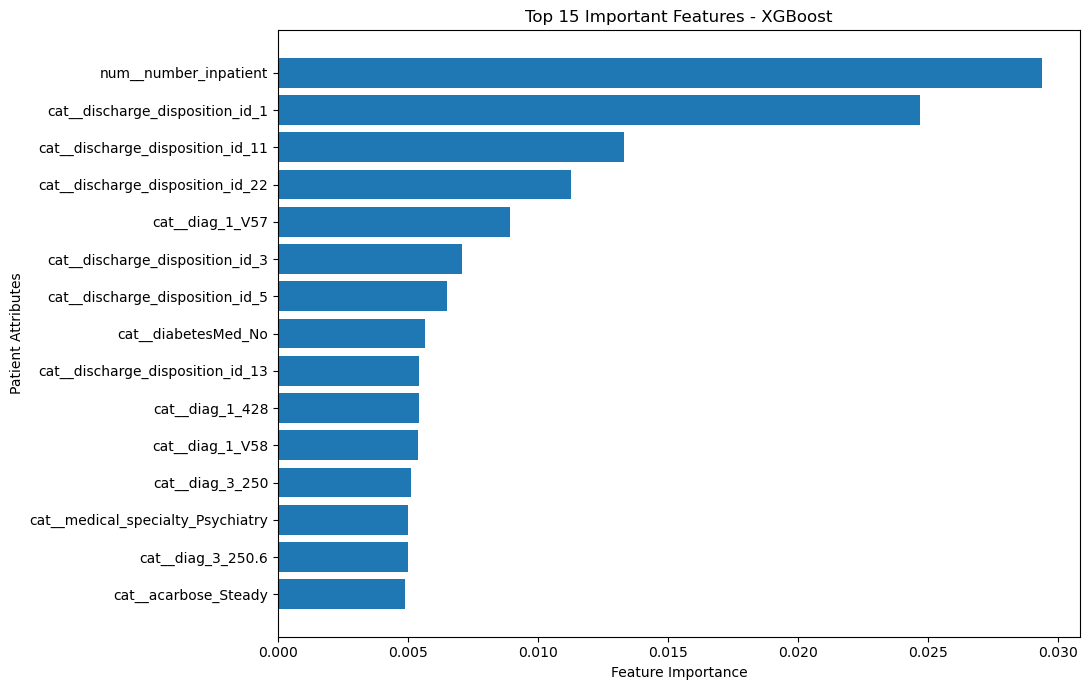

In [71]:
top_features = importance_df.head(15).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(11, 7))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Patient Attributes")
plt.title("Top 15 Important Features - XGBoost")

plt.tight_layout()
plt.show()

In [72]:
import os
import joblib

# Create models directory
os.makedirs("../models", exist_ok=True)

# Save final XGBoost model
joblib.dump(
    best_xgb,
    "../models/xgboost_model.pkl"
)

# Save preprocessing pipeline
joblib.dump(
    preprocessor,
    "../models/preprocessor.pkl"
)

# Save prediction threshold
joblib.dump(
    best_threshold,
    "../models/threshold.pkl"
)

# Save input feature names
joblib.dump(
    X_subtrain.columns.tolist(),
    "../models/input_features.pkl"
)

print("All model files saved successfully!")

All model files saved successfully!


In [73]:
# Inspect the saved preprocessing pipeline

print("Numerical columns:")
print(preprocessor.transformers_[0][2])

print("\nCategorical columns:")
print(preprocessor.transformers_[1][2])

print("\nNumber of input features:")
print(len(X_subtrain.columns))

print("\nNumber of transformed features:")
print(len(preprocessor.get_feature_names_out()))

print("\nModel expected features:")
print(best_xgb.n_features_in_)

# Inspect categorical encoder
encoder = preprocessor.named_transformers_["cat"]

print("\nEncoder categories:")
for col, categories in zip(
    preprocessor.transformers_[1][2],
    encoder.categories_
):
    print(col, ":", categories[:10])

Numerical columns:
['time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses']

Categorical columns:
['race', 'gender', 'age', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'payer_code', 'medical_specialty', 'diag_1', 'diag_2', 'diag_3', 'max_glu_serum', 'A1Cresult', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone', 'change', 'diabetesMed']

Number of input features:
44

Number of transformed features:
2344

Model expected features:
2344

Encoder categories:


AttributeError: 'Pipeline' object has no attribute 'categories_'

In [74]:
# Access the categorical pipeline
cat_pipeline = preprocessor.named_transformers_["cat"]

print("Categorical pipeline steps:")
print(cat_pipeline)

# Access the actual OneHotEncoder
encoder = cat_pipeline.named_steps["onehot"]

print("\nEncoder categories:")

for col, categories in zip(
    preprocessor.transformers_[1][2],
    encoder.categories_
):
    print(f"\n{col}:")
    print(categories[:10])

Categorical pipeline steps:
Pipeline(steps=[('encoder', OneHotEncoder(handle_unknown='ignore'))])


KeyError: 'onehot'

In [75]:
cat_pipeline = preprocessor.named_transformers_["cat"]

print("Categorical pipeline:")
print(cat_pipeline)

print("\nAvailable pipeline steps:")
print(cat_pipeline.named_steps.keys())

Categorical pipeline:
Pipeline(steps=[('encoder', OneHotEncoder(handle_unknown='ignore'))])

Available pipeline steps:
dict_keys(['encoder'])


In [76]:
from sklearn.preprocessing import OneHotEncoder

encoder = None

for name, step in cat_pipeline.named_steps.items():
    if isinstance(step, OneHotEncoder):
        encoder = step
        print("OneHotEncoder found in step:", name)
        break

if encoder is not None:
    for col, categories in zip(
        preprocessor.transformers_[1][2],
        encoder.categories_
    ):
        print(f"{col}: {categories[:10]}")
else:
    print("OneHotEncoder is nested inside another pipeline.")

OneHotEncoder found in step: encoder
race: ['AfricanAmerican' 'Asian' 'Caucasian' 'Hispanic' 'Other' 'Unknown']
gender: ['Female' 'Male' 'Unknown/Invalid']
age: ['[0-10)' '[10-20)' '[20-30)' '[30-40)' '[40-50)' '[50-60)' '[60-70)'
 '[70-80)' '[80-90)' '[90-100)']
admission_type_id: ['1' '2' '3' '4' '5' '6' '7' '8']
discharge_disposition_id: ['1' '10' '11' '12' '13' '14' '15' '16' '17' '18']
admission_source_id: ['1' '10' '11' '13' '14' '17' '2' '20' '22' '25']
payer_code: ['BC' 'CH' 'CM' 'CP' 'DM' 'HM' 'MC' 'MD' 'MP' 'OG']
medical_specialty: ['AllergyandImmunology' 'Anesthesiology' 'Anesthesiology-Pediatric'
 'Cardiology' 'Cardiology-Pediatric' 'DCPTEAM' 'Dentistry' 'Dermatology'
 'Emergency/Trauma' 'Endocrinology']
diag_1: ['11' '110' '112' '114' '117' '131' '135' '136' '141' '142']
diag_2: ['11' '110' '111' '112' '114' '117' '131' '135' '136' '137']
diag_3: ['110' '111' '112' '115' '117' '122' '123' '131' '135' '136']
max_glu_serum: ['>200' '>300' 'Norm' 'Not Tested']
A1Cresult: ['>7

In [77]:
import sys
import sklearn
import numpy
import xgboost

print("Python:", sys.executable)
print("Scikit-learn:", sklearn.__version__)
print("NumPy:", numpy.__version__)
print("XGBoost:", xgboost.__version__)

Python: c:\ProgramData\anaconda3\python.exe
Scikit-learn: 1.7.2
NumPy: 2.3.5
XGBoost: 3.4.1


In [78]:
import joblib
import os
import numpy as np

# Get numerical and categorical columns from fitted preprocessor
num_cols = preprocessor.transformers_[0][2]
cat_cols = preprocessor.transformers_[1][2]

# Store training data defaults and valid categorical options
feature_metadata = {
    "numerical_columns": list(num_cols),
    "categorical_columns": list(cat_cols),
    "defaults": {},
    "categorical_options": {}
}

for col in num_cols:
    feature_metadata["defaults"][col] = float(X_subtrain[col].median())

for col in cat_cols:
    values = X_subtrain[col].dropna().astype(str).unique().tolist()

    feature_metadata["categorical_options"][col] = values

    if len(values) > 0:
        feature_metadata["defaults"][col] = str(
            X_subtrain[col].mode().iloc[0]
        )

os.makedirs("../models", exist_ok=True)

joblib.dump(
    feature_metadata,
    "../models/feature_metadata.pkl"
)

print("Feature metadata saved successfully!")
print("Numerical features:", len(num_cols))
print("Categorical features:", len(cat_cols))
print("Total features:", len(num_cols) + len(cat_cols))

Feature metadata saved successfully!
Numerical features: 8
Categorical features: 36
Total features: 44


In [79]:
# Check which trained model objects are currently available

model_names = [
    "best_lr",
    "best_rf",
    "best_xgb",
    "lr_model",
    "rf_model",
    "logistic_model",
    "random_forest",
    "logistic_regression"
]

for name in model_names:
    if name in globals():
        obj = globals()[name]
        print(f"{name}: AVAILABLE - {type(obj).__name__}")
    else:
        print(f"{name}: NOT AVAILABLE")

best_lr: AVAILABLE - LogisticRegression
best_rf: AVAILABLE - RandomForestClassifier
best_xgb: AVAILABLE - XGBClassifier
lr_model: NOT AVAILABLE
rf_model: NOT AVAILABLE
logistic_model: NOT AVAILABLE
random_forest: NOT AVAILABLE
logistic_regression: NOT AVAILABLE


In [80]:
import os

model_dir = "../models"

print("Saved model files:")

for file in os.listdir(model_dir):
    if file.endswith(".pkl"):
        print(file)

Saved model files:
feature_metadata.pkl
input_features.pkl
preprocessed_data.pkl
preprocessor.pkl
threshold.pkl
xgboost_model.pkl


In [81]:
import joblib
import os

# Model directory
model_dir = "../models"

os.makedirs(model_dir, exist_ok=True)

# Save Logistic Regression
joblib.dump(
    best_lr,
    os.path.join(model_dir, "logistic_regression_model.pkl")
)

# Save Random Forest
joblib.dump(
    best_rf,
    os.path.join(model_dir, "random_forest_model.pkl")
)

print("Models saved successfully!")

print("Logistic Regression:", type(best_lr).__name__)
print("Random Forest:", type(best_rf).__name__)
print("XGBoost:", type(best_xgb).__name__)

Models saved successfully!
Logistic Regression: LogisticRegression
Random Forest: RandomForestClassifier
XGBoost: XGBClassifier


In [82]:
import joblib
import os
import numpy as np

from sklearn.metrics import (
    precision_recall_curve,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Model directory
model_dir = "../models"
os.makedirs(model_dir, exist_ok=True)


# --------------------------------------------------
# 1. FUNCTION TO FIND BEST VALIDATION THRESHOLD
# --------------------------------------------------

def find_best_threshold(model, X_val, y_val):

    probabilities = model.predict_proba(X_val)[:, 1]

    precision, recall, thresholds = precision_recall_curve(
        y_val,
        probabilities
    )

    f1_scores = (
        2 * precision[:-1] * recall[:-1]
        / (precision[:-1] + recall[:-1] + 1e-10)
    )

    best_index = np.argmax(f1_scores)

    best_threshold = thresholds[best_index]

    return float(best_threshold)


# --------------------------------------------------
# 2. CALCULATE THRESHOLDS
# --------------------------------------------------

lr_threshold = find_best_threshold(
    best_lr,
    X_val_processed,
    y_val
)

rf_threshold = find_best_threshold(
    best_rf,
    X_val_processed,
    y_val
)

# Preserve your previously selected XGBoost threshold.
xgb_threshold = float(best_threshold)


# --------------------------------------------------
# 3. SAVE ALL THREE THRESHOLDS
# --------------------------------------------------

thresholds = {

    "Logistic Regression": lr_threshold,

    "Random Forest": rf_threshold,

    "XGBoost": xgb_threshold

}

joblib.dump(
    thresholds,
    os.path.join(model_dir, "model_thresholds.pkl")
)


# --------------------------------------------------
# 4. SAVE TRAINED MODELS
# --------------------------------------------------

joblib.dump(
    best_lr,
    os.path.join(model_dir, "logistic_regression_model.pkl")
)

joblib.dump(
    best_rf,
    os.path.join(model_dir, "random_forest_model.pkl")
)

joblib.dump(
    best_xgb,
    os.path.join(model_dir, "xgboost_model.pkl")
)


# --------------------------------------------------
# 5. DISPLAY RESULTS
# --------------------------------------------------

print("\nMODEL THRESHOLDS")
print("-" * 45)

for name, value in thresholds.items():
    print(f"{name}: {value:.4f}")


print("\nAll three trained models and thresholds saved!")


MODEL THRESHOLDS
---------------------------------------------
Logistic Regression: 0.5032
Random Forest: 0.5146
XGBoost: 0.5376

All three trained models and thresholds saved!


In [83]:
import joblib
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

# Load individual thresholds
thresholds = joblib.load("../models/model_thresholds.pkl")

models = {
    "Logistic Regression": best_lr,
    "Random Forest": best_rf,
    "XGBoost": best_xgb
}

results = []
confusion_matrices = {}

# Evaluate all models on the same untouched test set
for name, model in models.items():

    probabilities = model.predict_proba(X_test_processed)[:, 1]

    threshold = thresholds[name]

    predictions = (probabilities >= threshold).astype(int)

    accuracy = accuracy_score(y_test, predictions)
    precision = precision_score(y_test, predictions, zero_division=0)
    recall = recall_score(y_test, predictions, zero_division=0)
    f1 = f1_score(y_test, predictions, zero_division=0)
    auc = roc_auc_score(y_test, probabilities)

    results.append({
        "Model": name,
        "Threshold": threshold,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "ROC-AUC": auc
    })

    confusion_matrices[name] = confusion_matrix(
        y_test, predictions
    )

# Create comparison table
evaluation_df = pd.DataFrame(results)

print("\nFINAL MODEL COMPARISON")
display(
    evaluation_df.style.format({
        "Threshold": "{:.4f}",
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1 Score": "{:.4f}",
        "ROC-AUC": "{:.4f}"
    })
)

# Save evaluation results
joblib.dump(
    evaluation_df,
    "../models/model_evaluation.pkl"
)

joblib.dump(
    confusion_matrices,
    "../models/confusion_matrices.pkl"
)

evaluation_df.to_csv(
    "../results/model_comparison.csv",
    index=False
)

print("\nEvaluation results saved successfully!")


FINAL MODEL COMPARISON


,Model,Threshold,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.5032,0.6805,0.1767,0.5449,0.2669,0.6722
1,Random Forest,0.5146,0.7560,0.1959,0.4142,0.2660,0.6735
2,XGBoost,0.5376,0.7302,0.1917,0.4751,0.2732,0.6745



Evaluation results saved successfully!


In [84]:
# Check available test dataset variables
for name in ["X_test", "X_test_scaled", "X_test_processed",
             "X_test_transformed", "y_test"]:
    if name in globals():
        value = globals()[name]
        print(name, ":", value.shape)

X_test : (20153, 44)
X_test_processed : (20153, 2344)
y_test : (20153,)


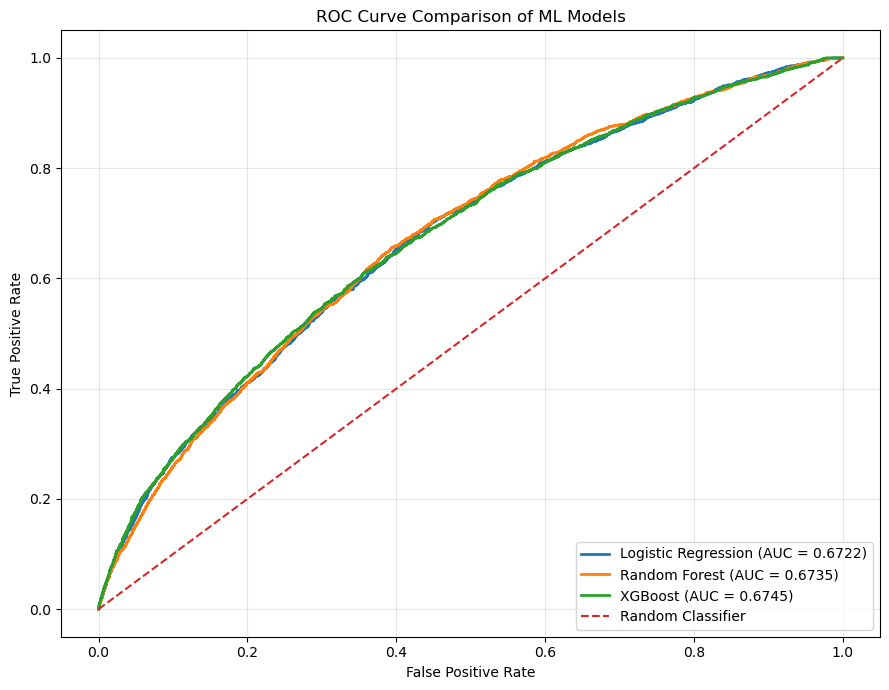

ROC curve saved successfully!


In [85]:
import numpy as np
import matplotlib.pyplot as plt
import joblib
import os

from sklearn.metrics import roc_curve, roc_auc_score

# Load trained models
models = {
    "Logistic Regression": best_lr,
    "Random Forest": best_rf,
    "XGBoost": best_xgb
}

# Create ROC curve
plt.figure(figsize=(9, 7))

for name, model in models.items():

    # Get predicted probabilities
    y_probability = model.predict_proba(X_test_processed)[:, 1]

    # Calculate ROC values
    fpr, tpr, thresholds = roc_curve(y_test, y_probability)

    # Calculate AUC
    auc_score = roc_auc_score(y_test, y_probability)

    # Plot curve
    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{name} (AUC = {auc_score:.4f})"
    )

# Random classifier reference line
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison of ML Models")

plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()

# Save graph
os.makedirs("../results", exist_ok=True)

plt.savefig(
    "../results/roc_curve_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("ROC curve saved successfully!")